# 04 — Results and analysis

Compares every system on the 480-pair **test set**: the two baselines (copy the input, zero-shot FLAN-T5) and the three fine-tuned runs, plus greedy decoding for the main run. Everything here is read from files in `runs/`; nothing is generated, so the notebook runs in a few seconds on a laptop.

Metrics (see `src/eval/metrics.py`): SARI and its three parts, BLEU, ROUGE, FKGL readability (lower = easier), length, copied trigrams (how much is copied word for word from the source), and unsupported numbers (numbers that appear nowhere in the source).

Figures are saved to `docs/figures/` for the report.

In [1]:
import json, os, sys
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.eval.metrics import _get_sari, compute_all, unsupported_numbers
from src.eval.readability import fkgl

FIG = Path("docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
SYSTEMS = {  # label -> folder with predictions.jsonl + metrics.json
    "Copy input":          "runs/baseline_copy",
    "Zero-shot":           "runs/baseline_zeroshot",
    "Main (beam 4)":       "runs/flan-t5-base_lr3e-4_src1024/test_beam4",
    "Main (greedy)":       "runs/flan-t5-base_lr3e-4_src1024/test_greedy",
    "lr 1e-4 (beam 4)":    "runs/flan-t5-base_lr1e-4_src1024/test_beam4",
    "512 tokens (beam 4)": "runs/flan-t5-base_lr3e-4_src512/test_beam4",
}
metrics = {k: json.load(open(f"{v}/metrics.json")) for k, v in SYSTEMS.items()}
preds = {k: [json.loads(l) for l in open(f"{v}/predictions.jsonl")] for k, v in SYSTEMS.items()}
rows = preds["Copy input"]                      # id, source, reference (same order everywhere)
sources = [r["source"] for r in rows]; references = [r["reference"] for r in rows]
assert all([p["id"] for p in v] == [r["id"] for r in rows] for v in preds.values())

# Chart style: recessive axes and grid, text in ink colors, one hue for single-series charts.
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
print(len(rows), "test examples,", len(SYSTEMS), "systems")

W1126 05:26:01.527000 32417 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


480 test examples, 6 systems


## 1. Results table

In [2]:
cols = {"sari": "SARI", "sari_keep": "keep", "sari_delete": "delete", "sari_add": "add",
        "bleu": "BLEU", "rougeL": "ROUGE-L", "fkgl_prediction": "FKGL", "words_prediction": "words",
        "copied_trigrams": "copied %", "unsupported_numbers": "unsupp. num. %"}
table = pd.DataFrame({k: {c: m[c] for c in cols} for k, m in metrics.items()}).T.rename(columns=cols)
ref = metrics["Copy input"]
table.loc["Human reference"] = {"FKGL": ref["fkgl_reference"],
                                "words": round(np.mean([len(r.split()) for r in references]), 2),
                                "copied %": ref["copied_trigrams_reference"],
                                "unsupp. num. %": ref["unsupported_numbers_reference"]}
table.to_csv("docs/results_test.csv")
print(f"Source abstracts: FKGL {ref['fkgl_source']}, {ref['words_prediction']} words on average")
display(table)

Source abstracts: FKGL 15.15, 349.82 words on average


,SARI,keep,delete,add,BLEU,ROUGE-L,FKGL,words,copied %,unsupp. num. %
Copy input,41.81,25.42,100.00,0.00,14.47,25.79,15.15,349.82,100.00,0.00
Zero-shot,33.63,16.97,83.66,0.26,0.46,14.29,13.99,44.30,84.20,2.20
Main (beam 4),37.90,28.51,82.85,2.35,14.78,25.54,14.07,184.40,78.59,2.84
Main (greedy),38.76,29.49,83.73,3.06,14.89,25.59,13.56,205.01,63.83,11.51
lr 1e-4 (beam 4),37.84,28.56,82.87,2.08,15.03,25.64,14.26,191.11,79.63,3.22
512 tokens (beam 4),37.74,27.68,82.76,2.77,13.09,24.87,13.89,171.51,73.43,4.04
Human reference,NaN,NaN,NaN,NaN,NaN,NaN,13.63,214.51,17.39,34.67


**How to read SARI here.** SARI is the mean of three parts: *keep* (kept the right source words), *delete* (removed the right ones) and *add* (added the right new words). The implementation scores "deleted nothing" as a perfect deletion (0/0 = 1), so **copying the input gets 100 for delete for free**. Every system that actually shortens the text can only lose there. On the two parts that measure real work, *keep* and *add*, the fine-tuned models beat copying.

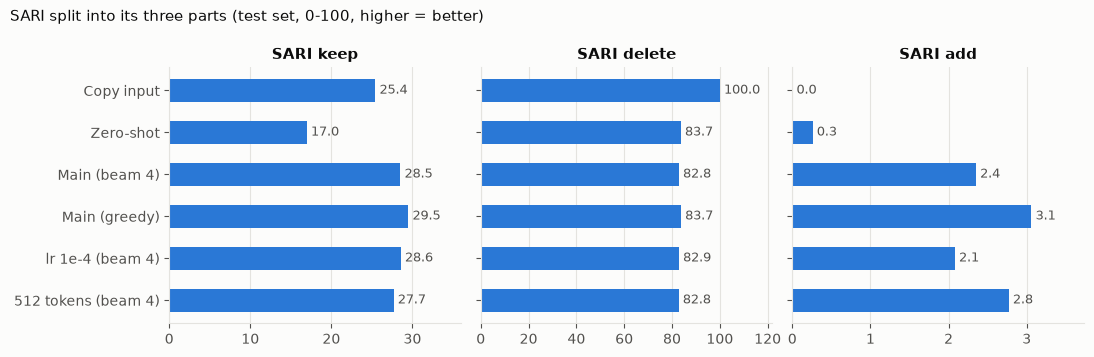

In [3]:
parts = [("sari_keep", "Keep"), ("sari_delete", "Delete"), ("sari_add", "Add")]
labels = list(SYSTEMS)[::-1]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (key, title) in zip(axes, parts):
    vals = [metrics[s][key] for s in labels]
    bars = ax.barh(labels, vals, height=0.55, color=BLUE)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in vals], padding=3, color=INK2, fontsize=9)
    ax.set_title(f"SARI {title.lower()}")
    ax.set_xlim(0, max(vals) * 1.22)
    ax.grid(axis="y", visible=False)
fig.suptitle("SARI split into its three parts (test set, 0-100, higher = better)", x=0.01, ha="left",
             fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(FIG / "sari_components.png", dpi=150); plt.show()

## 2. Training: validation loss of the three runs

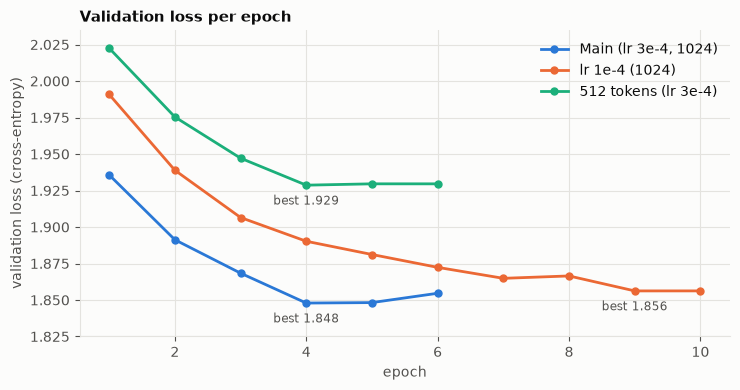

In [4]:
RUNS3 = {"Main (lr 3e-4, 1024)": "flan-t5-base_lr3e-4_src1024",
         "lr 1e-4 (1024)": "flan-t5-base_lr1e-4_src1024",
         "512 tokens (lr 3e-4)": "flan-t5-base_lr3e-4_src512"}
fig, ax = plt.subplots(figsize=(7.5, 4))
for (label, run), color in zip(RUNS3.items(), [BLUE, ORANGE, AQUA]):
    log = pd.read_csv(f"runs/{run}/log_history.csv").dropna(subset=["eval_loss"])
    log = log.drop_duplicates("epoch", keep="last")
    ax.plot(log["epoch"], log["eval_loss"], color=color, lw=2, marker="o", ms=5, label=label)
    best = log.loc[log["eval_loss"].idxmin()]
    ax.annotate(f"best {best['eval_loss']:.3f}", (best["epoch"], best["eval_loss"]),
                textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8.5, color=INK2)
ax.set_ylim(1.825, 2.035)
ax.set_xlabel("epoch"); ax.set_ylabel("validation loss (cross-entropy)")
ax.set_title("Validation loss per epoch", loc="left")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "val_loss_runs.png", dpi=150); plt.show()

## 3. Readability (FKGL, lower = easier)

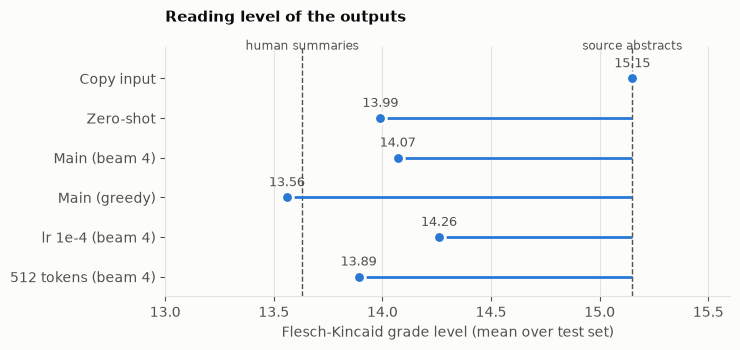

Main model: output easier than its source for 77% of examples; median change -0.84 grades


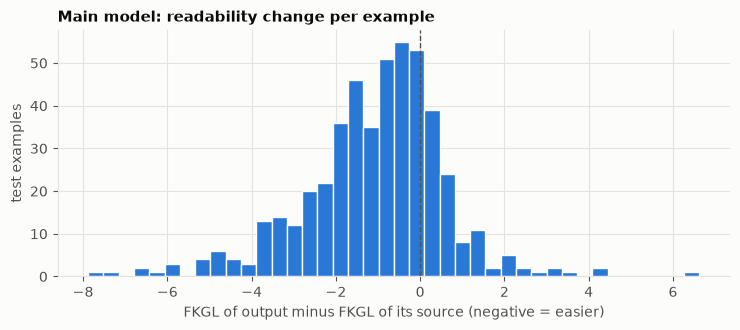

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
vals = [metrics[s]["fkgl_prediction"] for s in labels]
# Dot plot (FKGL has no meaningful zero, so no bars): each line runs from the
# source abstracts' level to the system's level.
ys = np.arange(len(labels))
ax.hlines(ys, ref["fkgl_source"], vals, color=BLUE, lw=2, zorder=2)
ax.scatter(vals, ys, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
for y, v in zip(ys, vals):
    ax.annotate(f"{v:.2f}", (v, y), textcoords="offset points", xytext=(0, 8), ha="center",
                fontsize=9, color=INK2)
ax.set_yticks(ys, labels)
for x, name in [(ref["fkgl_source"], "source abstracts"), (ref["fkgl_reference"], "human summaries")]:
    ax.axvline(x, color=INK2, lw=1, ls="--", zorder=0.5)
    ax.text(x, len(labels) - 0.35, name, rotation=0, ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.set_xlim(13, 15.6); ax.set_ylim(-0.5, len(labels) - 0.2); ax.grid(axis="y", visible=False)
ax.set_xlabel("Flesch-Kincaid grade level (mean over test set)")
ax.set_title("Reading level of the outputs", loc="left", pad=18)
fig.tight_layout(); fig.savefig(FIG / "fkgl_systems.png", dpi=150); plt.show()

main = [p["prediction"] for p in preds["Main (beam 4)"]]
diff = np.array([fkgl(p) - fkgl(s) for p, s in zip(main, sources)])
print(f"Main model: output easier than its source for {np.mean(diff < 0):.0%} of examples; "
      f"median change {np.median(diff):+.2f} grades")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(diff, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(0, color=INK2, lw=1, ls="--")
ax.set_xlabel("FKGL of output minus FKGL of its source (negative = easier)")
ax.set_ylabel("test examples")
ax.set_title("Main model: readability change per example", loc="left")
fig.tight_layout(); fig.savefig(FIG / "fkgl_change_main.png", dpi=150); plt.show()

## 4. Copying vs. invented numbers
Each point is one system. Right = copies more of the source word for word; up = more numbers that are not in the source.

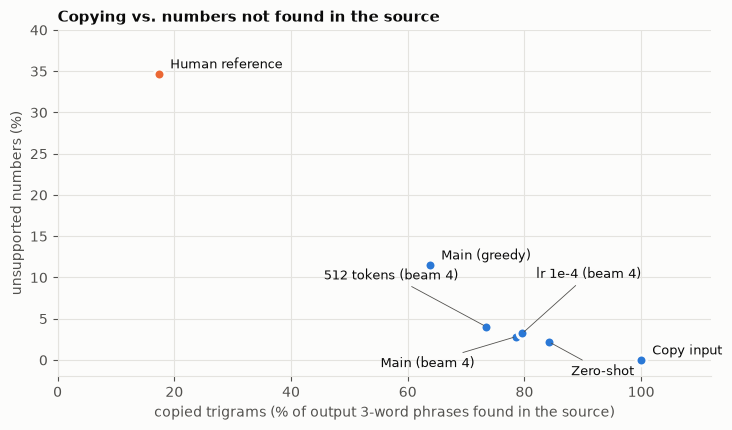

In [6]:
points = {s: (metrics[s]["copied_trigrams"], metrics[s]["unsupported_numbers"]) for s in SYSTEMS}
points["Human reference"] = (ref["copied_trigrams_reference"], ref["unsupported_numbers_reference"])
OFFSETS = {"512 tokens (beam 4)": (-20, 34, "right"), "lr 1e-4 (beam 4)": (10, 40, "left"),
           "Main (beam 4)": (-30, -22, "right"), "Zero-shot": (16, -24, "left")}
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for name, (x, y) in points.items():
    human = name == "Human reference"
    ax.scatter(x, y, s=60, color=ORANGE if human else BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    dx, dy, ha = OFFSETS.get(name, (8, 4, "left"))
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=9,
                color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6) if abs(dy) > 8 else None)
ax.set_xlim(0, 112); ax.set_ylim(-2, 40)
ax.set_xlabel("copied trigrams (% of output 3-word phrases found in the source)")
ax.set_ylabel("unsupported numbers (%)")
ax.set_title("Copying vs. numbers not found in the source", loc="left")
fig.tight_layout(); fig.savefig(FIG / "copying_vs_numbers.png", dpi=150); plt.show()

## 5. Are the differences real? (bootstrap)
SARI is an average over 480 examples, so small differences can be noise. The bootstrap resamples the 480 test examples with replacement 2,000 times and recomputes the score. A 95% interval that excludes 0 for a difference means the difference is unlikely to be chance. The comparisons are *paired*: both systems are scored on the same resampled examples.

In [7]:
sari_mod = sys.modules[type(_get_sari()).__module__]
def sari_per_example(outputs):
    return np.array([100 * sari_mod.SARIsent(sari_mod.normalize(s), sari_mod.normalize(o),
                                             [sari_mod.normalize(r)])
                     for s, o, r in zip(sources, outputs, references)])
per_ex = {s: sari_per_example([p["prediction"] for p in preds[s]]) for s in SYSTEMS}
for s in SYSTEMS:   # per-example mean must equal the reported corpus SARI
    assert abs(per_ex[s].mean() - metrics[s]["sari"]) < 0.01, s

rng = np.random.default_rng(0)
idx = rng.integers(0, len(rows), size=(2000, len(rows)))
def ci(x):
    boot = x[idx].mean(axis=1)
    return x.mean(), *np.percentile(boot, [2.5, 97.5])
out = []
for s in SYSTEMS:
    m, lo, hi = ci(per_ex[s]); out.append((s, "SARI", m, lo, hi))
for a, b in [("Main (beam 4)", "Copy input"), ("Main (beam 4)", "Zero-shot"),
             ("Main (greedy)", "Main (beam 4)"), ("Main (beam 4)", "lr 1e-4 (beam 4)"),
             ("Main (beam 4)", "512 tokens (beam 4)")]:
    m, lo, hi = ci(per_ex[a] - per_ex[b]); out.append((f"{a} minus {b}", "SARI difference", m, lo, hi))
boot_table = pd.DataFrame(out, columns=["system / comparison", "quantity", "mean", "95% low", "95% high"]).round(2)
boot_table.to_csv("docs/results_bootstrap.csv", index=False)
display(boot_table)

,system / comparison,quantity,mean,95% low,95% high
0,Copy input,SARI,41.81,41.43,42.19
1,Zero-shot,SARI,33.63,33.21,34.07
2,Main (beam 4),SARI,37.90,37.56,38.23
3,Main (greedy),SARI,38.76,38.38,39.12
4,lr 1e-4 (beam 4),SARI,37.84,37.47,38.18
5,512 tokens (beam 4),SARI,37.74,37.37,38.10
6,Main (beam 4) minus Copy input,SARI difference,-3.90,-4.39,-3.43
7,Main (beam 4) minus Zero-shot,SARI difference,4.28,3.71,4.81
8,Main (greedy) minus Main (beam 4),SARI difference,0.86,0.48,1.24
9,Main (beam 4) minus lr 1e-4 (beam 4),SARI difference,0.07,-0.25,0.37


## 6. Long abstracts: what truncating to 512 tokens costs
Only the test abstracts longer than 512 tokens are affected by the 512-token model's cut-off. Compare the two lr 3e-4 models on those examples and on the rest.

In [8]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("google/flan-t5-base")
n_tok = np.array([len(tok("simplify: " + s)["input_ids"]) for s in sources])
long_ = n_tok > 512
print(f"{long_.sum()} of {len(rows)} test sources are longer than 512 tokens "
      f"({long_.mean():.0%}); {(n_tok > 1024).sum()} are longer than 1024")
res = []
for name, mask in [("longer than 512 tokens", long_), ("512 tokens or shorter", ~long_)]:
    for s in ["Main (beam 4)", "512 tokens (beam 4)"]:
        sel = [i for i in range(len(rows)) if mask[i]]
        out_s = [preds[s][i]["prediction"] for i in sel]
        src_s = [sources[i] for i in sel]
        res.append({"inputs": name, "system": s, "n": len(sel),
                    "SARI": round(per_ex[s][sel].mean(), 2),
                    "unsupp. num. %": round(unsupported_numbers(src_s, out_s), 2),
                    "words": round(np.mean([len(o.split()) for o in out_s]), 1)})
display(pd.DataFrame(res))

# Paired bootstrap of the SARI difference (main minus 512-token model) on each subset
for name, mask in [("longer than 512 tokens", long_), ("512 tokens or shorter", ~long_)]:
    d = (per_ex["Main (beam 4)"] - per_ex["512 tokens (beam 4)"])[mask]
    b = d[rng.integers(0, len(d), size=(2000, len(d)))].mean(axis=1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    print(f"{name}: main minus 512-token SARI = {d.mean():+.2f} (95% CI {lo:+.2f} to {hi:+.2f})")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1002 > 512). Running this sequence through the model will result in indexing errors


235 of 480 test sources are longer than 512 tokens (49%); 8 are longer than 1024


,inputs,system,n,SARI,unsupp. num. %,words
0,longer than 512 tokens,Main (beam 4),235,38.27,2.99,227.9
1,longer than 512 tokens,512 tokens (beam 4),235,37.70,4.44,209.2
2,512 tokens or shorter,Main (beam 4),245,37.55,2.56,142.6
3,512 tokens or shorter,512 tokens (beam 4),245,37.77,3.26,135.4


longer than 512 tokens: main minus 512-token SARI = +0.56 (95% CI +0.08 to +1.02)
512 tokens or shorter: main minus 512-token SARI = -0.22 (95% CI -0.76 to +0.37)


## 7. Examples
Picked automatically from the main model (beam 4), so they are not cherry-picked by hand: the example with the highest SARI, one at the median, the lowest, and the one with the most unsupported numbers. Texts are shortened to 900 characters.

In [9]:
import re, textwrap
def numbers(t): return [n.replace(",", "") for n in re.findall(r"\d+(?:[.,]\d+)*", t)]
def n_unsupported(src, out): return sum(n not in set(numbers(src)) for n in numbers(out))
scores = per_ex["Main (beam 4)"]
order = np.argsort(scores)
picks = {"highest SARI": order[-1], "median SARI": order[len(order) // 2], "lowest SARI": order[0],
         "most unsupported numbers": int(np.argmax([n_unsupported(s, p["prediction"])
                                                     for s, p in zip(sources, preds["Main (beam 4)"])]))}
def show(label, text):
    print(f"{label}:"); print(textwrap.fill(text[:900] + (" [...]" if len(text) > 900 else ""), 110,
                                              initial_indent="  ", subsequent_indent="  "))
for name, i in picks.items():
    p = preds["Main (beam 4)"][i]["prediction"]
    print("=" * 110); print(f"{name.upper()}  |  {rows[i]['id']}  |  SARI {scores[i]:.1f}  |  "
                            f"FKGL source {fkgl(sources[i]):.1f} -> output {fkgl(p):.1f}  |  "
                            f"unsupported numbers {n_unsupported(sources[i], p)}")
    show("SOURCE", sources[i]); show("HUMAN SUMMARY", references[i]); show("MODEL (main, beam 4)", p)

HIGHEST SARI  |  10.1002/14651858.CD006278.pub3  |  SARI 50.9  |  FKGL source 15.0 -> output 14.0  |  unsupported numbers 0
SOURCE:
  This review includes only one RCT, funded by the Australian Research Council; the University of Sydney
  International Development Fund; Douglas and Lola Douglas Scholarship on Child and Adolescent Health; Nadia
  Verrall Memorial Scholarship; and a James Kentley Memorial Fellowship. This study recruited 26 children aged
  4 to 12 years, with mild to moderate CAS of unknown cause, and compared two interventions: the Nuffield
  Dyspraxia Programme-3 (NDP-3); and the Rapid Syllable Transitions Treatment (ReST). Children were allocated
  randomly to one of the two treatments. Treatments were delivered intensively in one-hour sessions, four days
  a week for three weeks, in a university clinic in Australia. Speech pathology students delivered the
  treatments in the English language. Outcomes were assessed before therapy, immediately after therapy, at one
  

In [10]:
# The same abstract with beam search and greedy decoding: the example where greedy
# writes the most numbers that are not in the source.
gaps = [n_unsupported(s, g["prediction"]) - n_unsupported(s, b["prediction"])
        for s, g, b in zip(sources, preds["Main (greedy)"], preds["Main (beam 4)"])]
i = int(np.argmax(gaps))
print(rows[i]["id"], "| unsupported numbers: beam", n_unsupported(sources[i], preds["Main (beam 4)"][i]["prediction"]),
      "| greedy", n_unsupported(sources[i], preds["Main (greedy)"][i]["prediction"]))
show("SOURCE", sources[i]); show("BEAM 4", preds["Main (beam 4)"][i]["prediction"])
show("GREEDY", preds["Main (greedy)"][i]["prediction"])

10.1002/14651858.CD007030.pub3 | unsupported numbers: beam 0 | greedy 16
SOURCE:
  We retrieved 12,490 citations, obtained full texts for 58 studies and included 12 trials (three from the
  2008 search and nine from the 2014 search) with 703 participants. Eight trials primarily investigated the
  efficacy in treating PSF, of which six trials with seven comparisons provided data suitable for meta-
  analysis (five pharmacological interventions: fluoxetine, enerion, (-)-OSU6162, citicoline and a combination
  of Chinese herbs; and two non-pharmacological interventions: a fatigue education programme and a
  mindfulness-based stress reduction programme). The fatigue severity was lower in the intervention groups
  than in the control groups (244 participants, pooled SMD -1.07, 95% confidence interval (CI) -1.93 to
  -0.21), with significant heterogeneity between trials (I2 = 87%, degrees of freedom (df) = 6, P value less
  than 0.00001). The beneficial effect was not seen in trials that had